# Modelo, limiar e submissão — ERAMIA-RS 2026

Este notebook repete o treino do pacote `desfecho`: logística com spline de idade, CatBoost, média das probabilidades, validação estratificada 5×5 e um limiar único. No Colab, a primeira célula de código clona o repositório se precisar e pede o CSV, que não está no git.

Leva cerca de um minuto em CPU. GPU não entra.


In [1]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not Path("src/desfecho").exists():
    subprocess.check_call(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/pedroohaubert/hospital-mortality-prediction.git",
            "hospital-mortality-prediction",
        ]
    )
    os.chdir("hospital-mortality-prediction")

ROOT = Path.cwd().resolve()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

if IN_COLAB:
    subprocess.check_call(
        [
            sys.executable, "-m", "pip", "install", "-q",
            "catboost==1.2.10",
            "scikit-learn==1.9.1",
            "pandas==3.1.1",
            "numpy==2.5.4",
            "scipy==1.18.1",
            "matplotlib==3.11.2",
            "joblib==1.6.0",
        ]
    )

DATA = ROOT / "data" / "final_treino_val.csv"
if not DATA.exists():
    if not IN_COLAB:
        raise SystemExit("Coloque o CSV em data/final_treino_val.csv. Ele não vem no git.")
    from google.colab import files
    print("Envie o final_treino_val.csv")
    uploaded = files.upload()
    DATA.parent.mkdir(parents=True, exist_ok=True)
    name = next(iter(uploaded))
    DATA.write_bytes(uploaded[name])
print("raiz", ROOT)
print("dados", DATA, "existe" if DATA.exists() else "ausente")


raiz /workspace
dados /workspace/data/final_treino_val.csv existe


## Treino

Os hiperparâmetros estão em `TrainConfig` e não são buscados nesta validação. O mesmo fold serve para a logística só com idade, a logística completa e o CatBoost. O limiar é escolhido na média out-of-fold, com piso de 8% de casos previstos como cura.


In [2]:
from desfecho.config import TrainConfig
from desfecho.cv import predict_proba, run_training
from desfecho.data import dataset_checks, load_table
from desfecho.store import save_training
from desfecho.submission import build_submission, validate_submission

frame = load_table(DATA, require_target=True)
checks = dataset_checks(frame)
cfg = TrainConfig()
print(
    f"n={checks['n']}  prevalência={checks['prevalencia_obito']:.3f}  "
    f"AUC do ID={checks['auc_id_numerico']:.3f}"
)
result = run_training(frame, cfg, log=print)
save_training(ROOT / "artifacts", result, checks)
metrics = result["metrics"]
shipped = metrics["modelo_submissao"]
block = metrics["modelos"][shipped]
point = metrics["ponto_oof"]
print("modelo", shipped)
print(
    f"AUC {block['auc_media_oof']:.3f}  "
    f"bootstrap {block['auc_bootstrap_ic95'][0]:.3f}–{block['auc_bootstrap_ic95'][1]:.3f}  "
    f"DeLong {block['auc_delong_ic95'][0]:.3f}–{block['auc_delong_ic95'][1]:.3f}"
)
print(
    f"limiar {metrics['limiar']:.6f}  LR− {point['lr_neg']:.4f}  "
    f"F1 {point['f1']:.4f}  sens {point['sensibilidade']:.3f}  "
    f"espec {point['especificidade']:.3f}"
)
nested = metrics["ponto_aninhado_media"]
print(
    f"LR− com limiar escolhido fora da repetição: média {nested['lr_neg_media']:.4f}  "
    f"F1 média {nested['f1_media']:.4f}"
)
print(metrics["ponto_oof_aviso"])


n=6332  prevalência=0.572  AUC do ID=0.508


repetição 1/5 fold 1/5 AUC logística 0.733 CatBoost 0.733 árvores 248


repetição 1/5 fold 2/5 AUC logística 0.744 CatBoost 0.748 árvores 78


repetição 1/5 fold 3/5 AUC logística 0.718 CatBoost 0.712 árvores 39


repetição 1/5 fold 4/5 AUC logística 0.729 CatBoost 0.727 árvores 77


repetição 1/5 fold 5/5 AUC logística 0.738 CatBoost 0.747 árvores 157


... (18 outputs left out)

repetição 5/5 fold 4/5 AUC logística 0.730 CatBoost 0.734 árvores 72


repetição 5/5 fold 5/5 AUC logística 0.715 CatBoost 0.711 árvores 37
modelo que vai para a submissão: ensemble. Logística e CatBoost ficaram a até 0,02 de AUC. A submissão usa a média simples das probabilidades, com peso 0,5, sem reajustar peso na mesma validação.


limiar 0.276163 (principal) LR− 0.2143 F1 0.7431


modelo ensemble
AUC 0.737  bootstrap 0.725–0.750  DeLong 0.725–0.750
limiar 0.276163  LR− 0.2143  F1 0.7431  sens 0.969  espec 0.145
LR− com limiar escolhido fora da repetição: média 0.2205  F1 média 0.7439
Limiar escolhido nestes mesmos escores out-of-fold. O ponto daqui é otimista em relação a um conjunto novo.


A célula acima é a medição. O ponto de LR− e F1 no out-of-fold completo é otimista, porque o corte foi escolhido ali. A linha da repetição deixada de fora é a leitura mais cuidadosa do mesmo limiar. O arquivo de submissão usa um corte só, o gravado no modelo.


roc.png


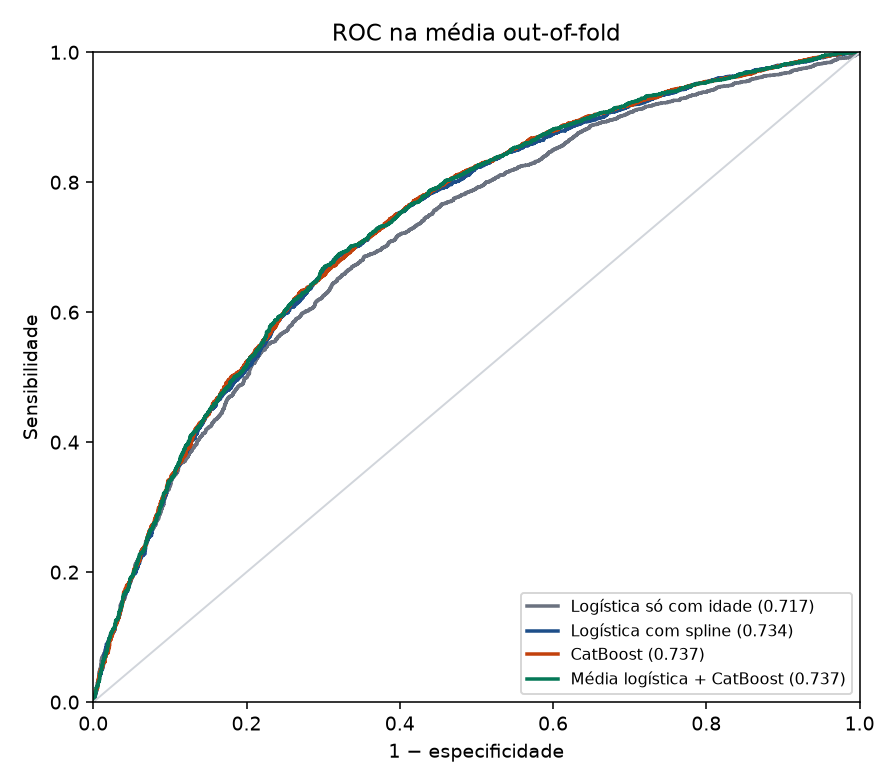

calibracao.png


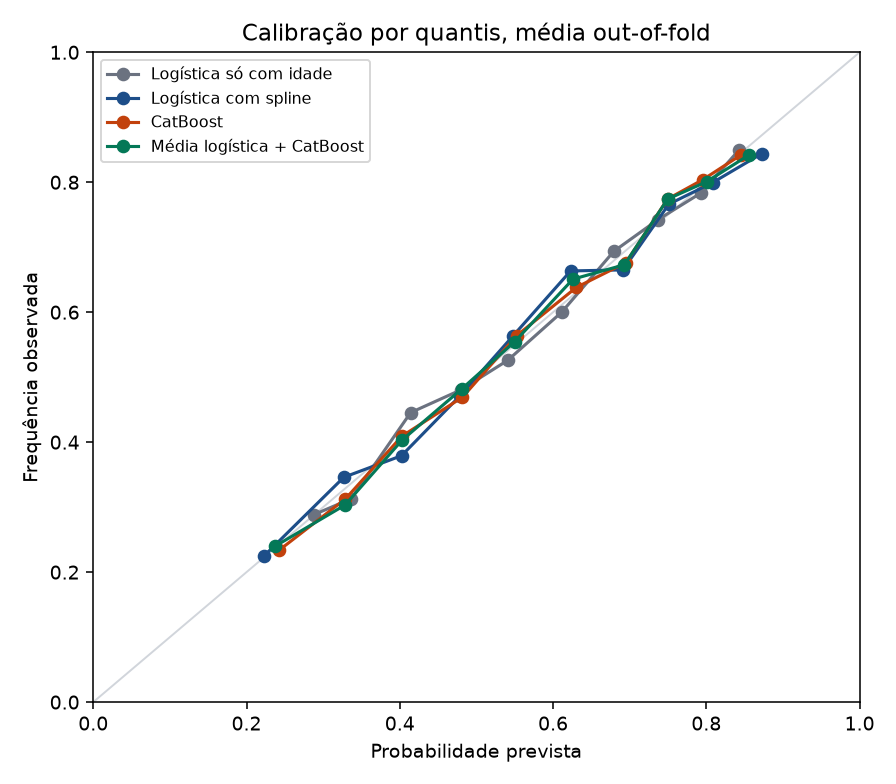

limiar.png


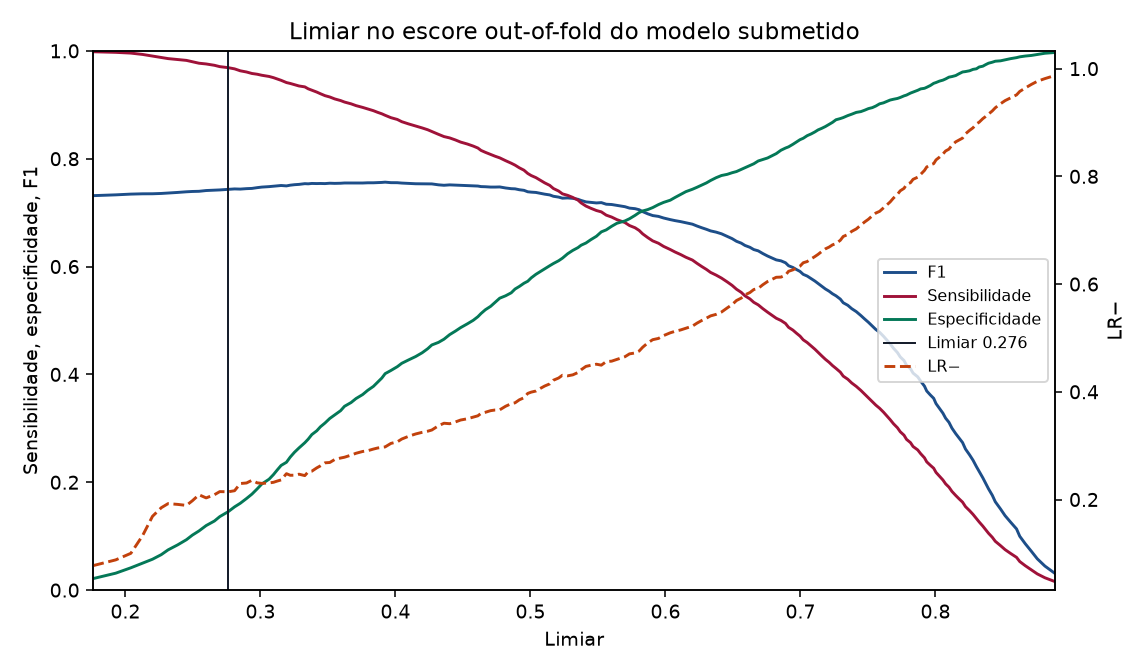

importancia.png


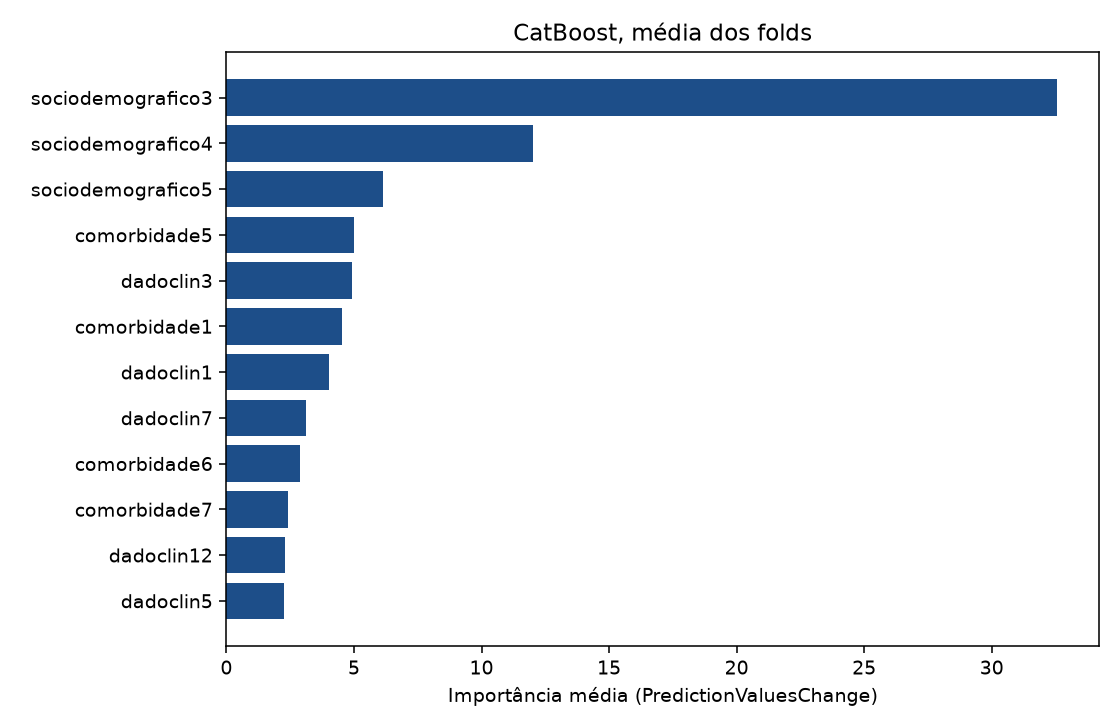

idade_efeito.png


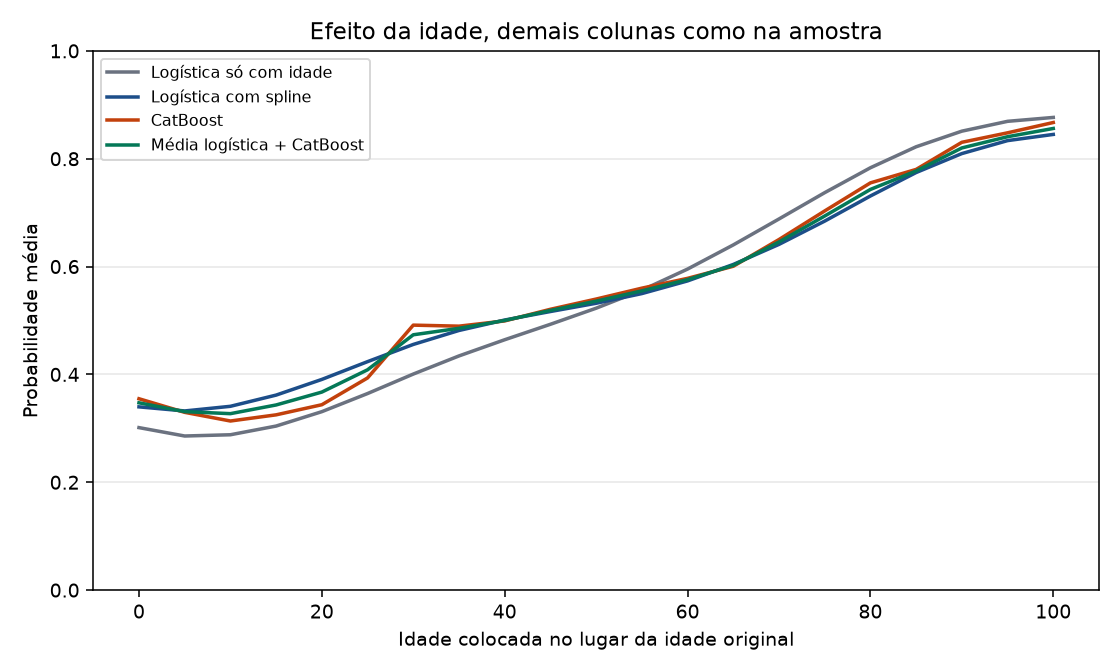

idade_treino.png


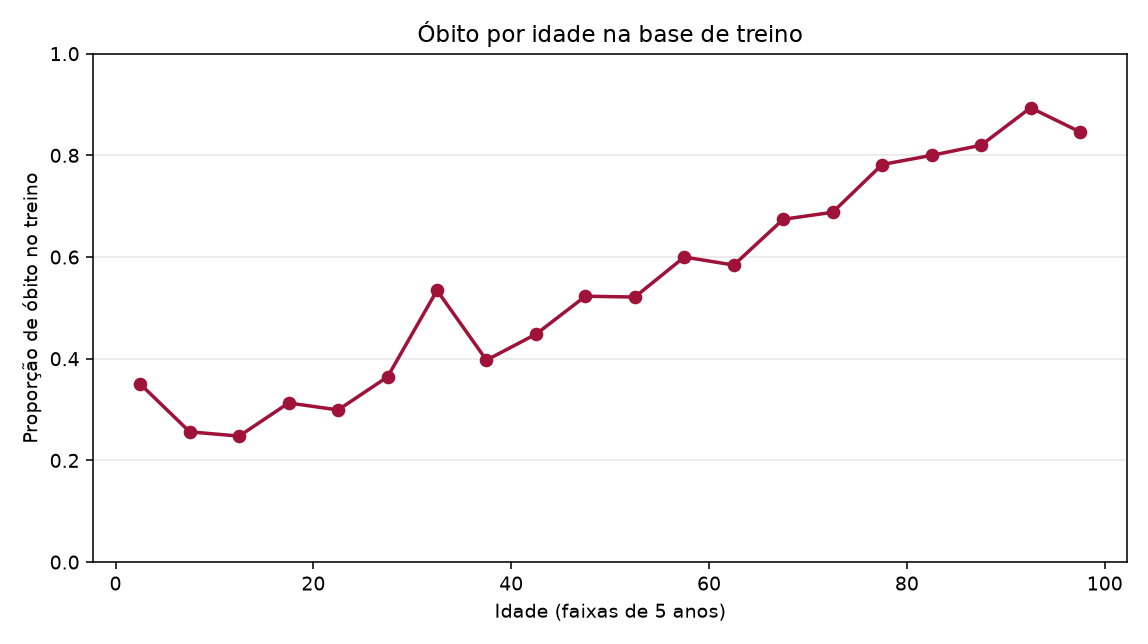

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display

from desfecho.viz import save_age_rate, save_figures

paths = save_figures(
    ROOT / "artifacts",
    metrics,
    result["oof"],
    result["explanation"],
    ROOT / "figs",
)
paths.append(save_age_rate(frame, ROOT / "figs" / "idade_treino.png"))
from IPython.display import Image

for path in paths:
    print(path.name)
    display(Image(filename=str(path)))


## Formato da submissão

O teste de 1.605 linhas ainda não existe. A célula abaixo tira o rótulo das primeiras linhas do treino e roda o mesmo `predict` que vai rodar no `teste.csv`. A probabilidade daqui não é nota de ranking: esses pacientes entraram em parte dos folds. É só o formato `id,prob,desfecho`, com o limiar gravado.


In [4]:
amostra = frame.drop(columns=["DESFECHO"]).head(8)
probs = predict_proba(result["bundle"], amostra)
sub = build_submission(amostra["ID"].tolist(), probs, result["bundle"]["threshold"])
validate_submission(sub, result["bundle"]["threshold"], expected_ids=amostra["ID"].tolist())
print(f"limiar usado {result['bundle']['threshold']:.6f}")
display(sub)


limiar usado 0.276163


,id,prob,desfecho
0,A608287,0.351128,1
1,A836141,0.666146,1
2,A244981,0.716171,1
3,A567520,0.658371,1
4,A819593,0.786811,1
5,A252479,0.274554,0
6,A214732,0.901197,1
7,A577506,0.802007,1


No dia, com o ambiente já instalado e sem rede:

```bash
uv run --offline desfecho predict --data teste.csv --out submissao.csv
```

A classe 1 é `prob >= limiar` na probabilidade de seis casas que foi escrita no arquivo. Se isso não fechar, o comando recusa gravar.
